# Applied Programming for AI
## Week 7 — Training, Validation and Model Selection with Movies
**Instructor solution · Python and scikit-learn**

Can the release year and genres of a film help estimate its average MovieLens rating?
We will build a k-nearest neighbours **regression** model and compare it with a simple baseline.
Predicting a number calls for `KNeighborsRegressor`, rather than `KNeighborsClassifier`.

In Week 5 you constructed preprocessing pipelines; in Week 6 you cleaned and explored a selected dataset.
Now we attach a model and investigate whether its performance is credible on unseen data.

### Learning outcomes
- Define predictors and a target without giving the model the answer.
- Separate training and test data before learning preprocessing statistics.
- Fit and evaluate a complete pipeline; interpret MAE in rating points.
- Distinguish training, validation, and test roles.
- Select hyperparameters with cross-validation and `GridSearchCV`.
- Interpret both model errors and the limits of the experimental design.

### How to use this notebook
The exercise gaps are completed and suggested answers are included. Restart the kernel and run all cells in order. Saved outputs show one verified run; small numerical differences may occur across package versions.

Keep `data/movies_modeling.csv` beside this notebook in the `data` folder. In Colab, upload the CSV using the Files panel; the loader also accepts it beside the notebook.

In [1]:
# Uncomment only if the course environment is missing packages.
# %pip install pandas numpy matplotlib "scikit-learn>=1.2"

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score
import sklearn

SEED = 42
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.6.1


## 1. Meet the movie table
The CSV is a teaching derivative of **MovieLens latest-small (2018 snapshot)**: one row per film with at least 20 ratings. `mean_rating` is the mean of the recorded 0.5–5 star ratings, not an objective measure of film quality.

| Column | Role |
| --- | --- |
| `movieId`, `title` | Audit/interpretation only; not predictors |
| `release_year` | Numeric predictor |
| `genre_profile` | Categorical predictor: the complete genre combination |
| `genre_count` | Numeric predictor |
| `rating_count` | Audit/selection field; excluded from predictors |
| `mean_rating` | Numeric target |

We use the full genre combination as one category to practise `OneHotEncoder`.

We are estimating observed average ratings for held-out films from this selected snapshot. We are **not** predicting individual users' preferences or proving that the model will work.

In [3]:
# Look beside the notebook, or in data/.
data_path = Path('data/movies_modeling.csv')
if not data_path.exists():
    data_path = Path('movies_modeling.csv')

movies = pd.read_csv(data_path)
display(movies.head())
print('Number of films:', len(movies))

,movieId,title,release_year,genre_profile,genre_count,rating_count,mean_rating
0,1,Toy Story (1995),1995,Adventure|Animation|Children|Comedy|Fantasy,5,215,3.920930
1,2,Jumanji (1995),1995,Adventure|Children|Fantasy,3,110,3.431818
2,3,Grumpier Old Men (1995),1995,Comedy|Romance,2,52,3.259615
3,5,Father of the Bride Part II (1995),1995,Comedy,1,49,3.071429
4,6,Heat (1995),1995,Action|Crime|Thriller,3,102,3.946078


Number of films: 1297


### Q1.1 — What are we predicting?
Each row is one film. Which column contains the number we want to predict? Why is this a regression problem?

**Suggested answer / teaching note**

The target is `mean_rating`, the average recorded rating for each film. It is regression because we predict a number, not a category.

### Q1.2 — Select X and y
**X = information about each film.** Use `feature_columns` in the first gap.

**y = the rating we want to predict.** Use `'mean_rating'` in the second gap.

Keep the rating out of X: otherwise the model receives the answer.

>**Note:**
>
>- X contains release year, genre combination and genre count.
>- y contains mean_rating.
>
>**The rating must not appear in X because it is the answer we want to predict.**

In [4]:
feature_columns = ['release_year', 'genre_profile', 'genre_count']
X = movies[feature_columns].copy()
y = movies['mean_rating'].copy()
print(X.shape, y.shape)
display(X.isna().sum())

(1297, 3) (1297,)


release_year     0
genre_profile    0
genre_count      0
dtype: int64

## 2. One split: training and final test
We create **only training and test sets**. Training data develop the model; the test stays reserved until the final evaluation.

Validation is still necessary, but cross-validation manages it **inside X_train**. There is no separate validation DataFrame to create or maintain.

>**Example:**
>
>Here `features` means your input table and `target` your target Series.
>
>Adapt those names to your dataset.
>```python
>from sklearn.model_selection import train_test_split
>
>X_train, X_test, y_train, y_test = train_test_split(
>    features, target, test_size=0.20, random_state=42
>)
>```

For our movie regression task, use X and y. For classification with enough examples per class, `stratify=target` can preserve proportions. Do not stratify directly on a continuous rating.

The diagram below shows validation rounds inside training. The purple final test remains untouched in every round.

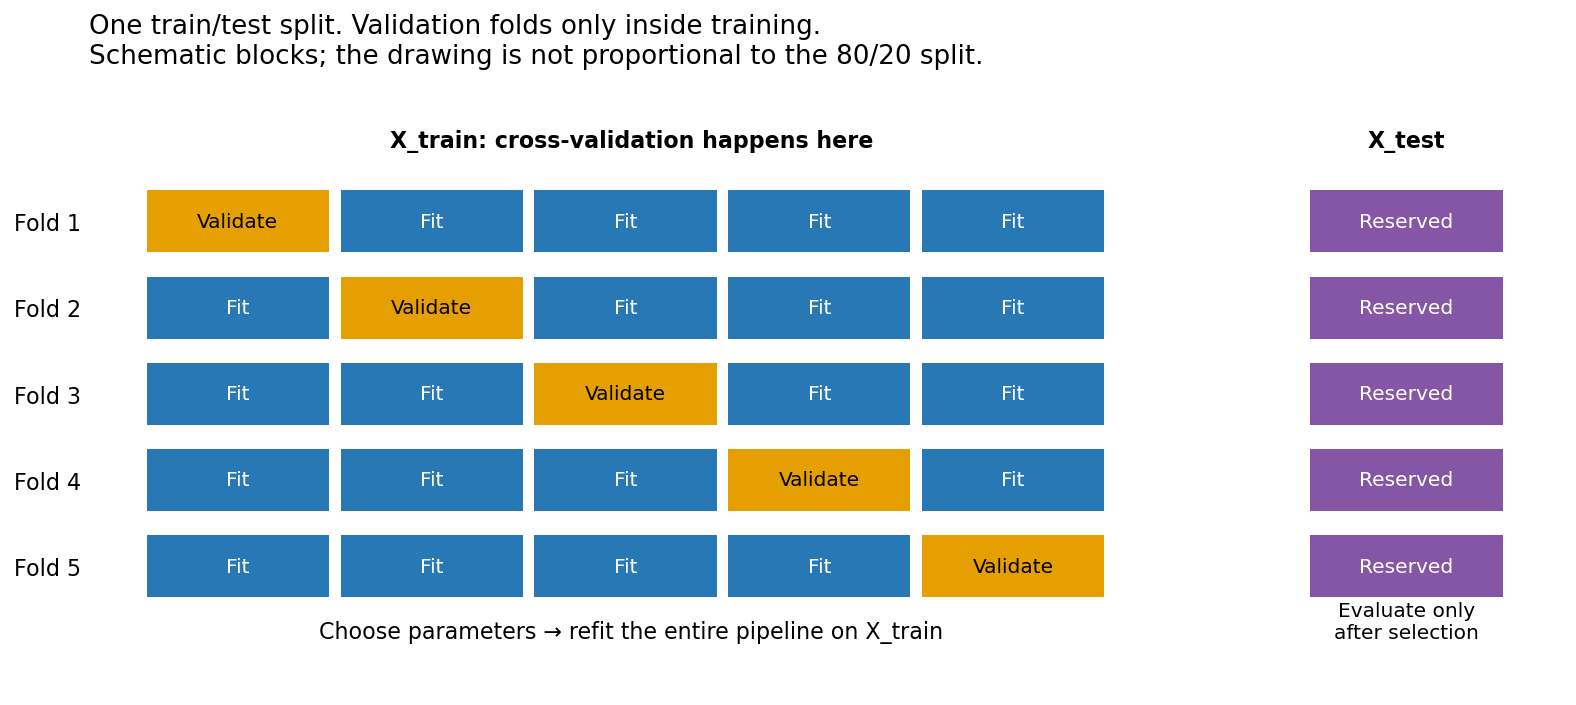

### Q2.1 — Keep 20% for the final test
Replace the gap with `0.20`. The other 80% is used to develop the model.

`random_state=SEED` makes the split repeatable. Do not try different seeds to get a better score.

>**Note:**
>
>- `test_size=0.20` reserves 20% for testing: 260 movies here.
>- The other 1,037 movies form the training set. Cross-validation uses only those training movies.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print('Training pool:', len(X_train), '| Reserved test:', len(X_test))

Training pool: 1037 | Reserved test: 260


### Q2.2 — Explain in your own words
Which set do we use to choose the model: training or test? Why do we keep the test separate?

>**Note**
>
>- We choose the model using cross-validation inside training data.
>- We keep the test separate to evaluate the chosen model on observations that did not guide its selection.

## 3. Add a model to the pipeline
The pipeline does two jobs: **prepare the data → make a prediction**.

| Method | What it does |
| --- | --- |
| `fit(X_train, y_train)` | Learns the preparation rules and fits the model using training data |
| `predict(X_test)` | Applies the same rules and predicts ratings for test films |

The preparation code below is provided. It fills missing numbers, scales numbers, and encodes categories. You do not need to rewrite it.

> **Important change from Week 5:** do not prepare all rows with `fit_transform` before splitting. Keep preparation inside the model pipeline.

k-NN predicts using similar training films. `n_neighbors=5` means using five neighbours. We will compare different values later.

In [6]:
numeric_features = ['release_year', 'genre_count']
categorical_features = ['genre_profile']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])

### Q3.1 — Connect preparation and prediction
Complete the gaps using `preprocessor`, `5`, `X_train`, and `y_train`, in that order.

This fits the pipeline. We have not yet measured how well it predicts new films.

>**Note**
>
>- The completed pipeline connects `preprocessor` to a `KNeighborsRegressor` with 5 neighbours, then fits on X_train and y_train.
>- This initial fit demonstrates the API; cross-validation later fits fresh copies within each fold.

In [7]:
model = Pipeline([
    ('preprocess', preprocessor),
    ('model', KNeighborsRegressor(n_neighbors=5)),
])
model.fit(X_train, y_train)
print('Pipeline fitted on training rows only.')

Pipeline fitted on training rows only.


## 4. Understand the error before comparing models
**Mean absolute error (MAE)** averages `abs(actual - predicted)`.

Smaller is better, in rating points. MAE of 0.4 means 0.4 points of average absolute error, not 40% accuracy.

>**Example**
>These numbers are unrelated to the movie test set. They illustrate the metric only.
>```python
>from sklearn.metrics import mean_absolute_error
>
>actual = [2.0, 4.0]
>predicted = [2.5, 3.0]
>print(mean_absolute_error(actual, predicted))  # 0.75
>```

The absolute errors are 0.5 and 1.0; their average is 0.75.

A **baseline** gives a simple comparison. `DummyRegressor(strategy='median')` predicts the training median regardless of movie features. We compare baseline and k-NN through CV later, not by repeatedly inspecting the test.

`KNeighborsRegressor.score` returns R², not MAE. **We request the intended metric explicitly.**

### Q4.1 — Practise MAE and define a baseline

- Calculate MAE for these fictional predictions.
- Then construct an unfitted median baseline for later cross-validation.
- Explain what its prediction will depend on.

>**Note**
>
>- The absolute errors are 0.5, 1.0 and 1.0, giving MAE = 2.5 / 3 ≈ **0.833 rating points**.
>- The median baseline predicts the median of the training targets. It does not use the film characteristics, and it must not use the test median.

In [8]:
actual_example = [2.0, 3.0, 5.0]
predicted_example = [2.5, 2.0, 4.0]
example_mae = mean_absolute_error(actual_example, predicted_example)
print('Example MAE:', example_mae)
baseline = DummyRegressor(strategy='median')

Example MAE: 0.8333333333333334


## 5. Leakage — when the model gets information it should not have
Think of the final test as an exam. We must not use its answers while preparing the model.

**The red lines below are wrong. These examples are for reading only.**

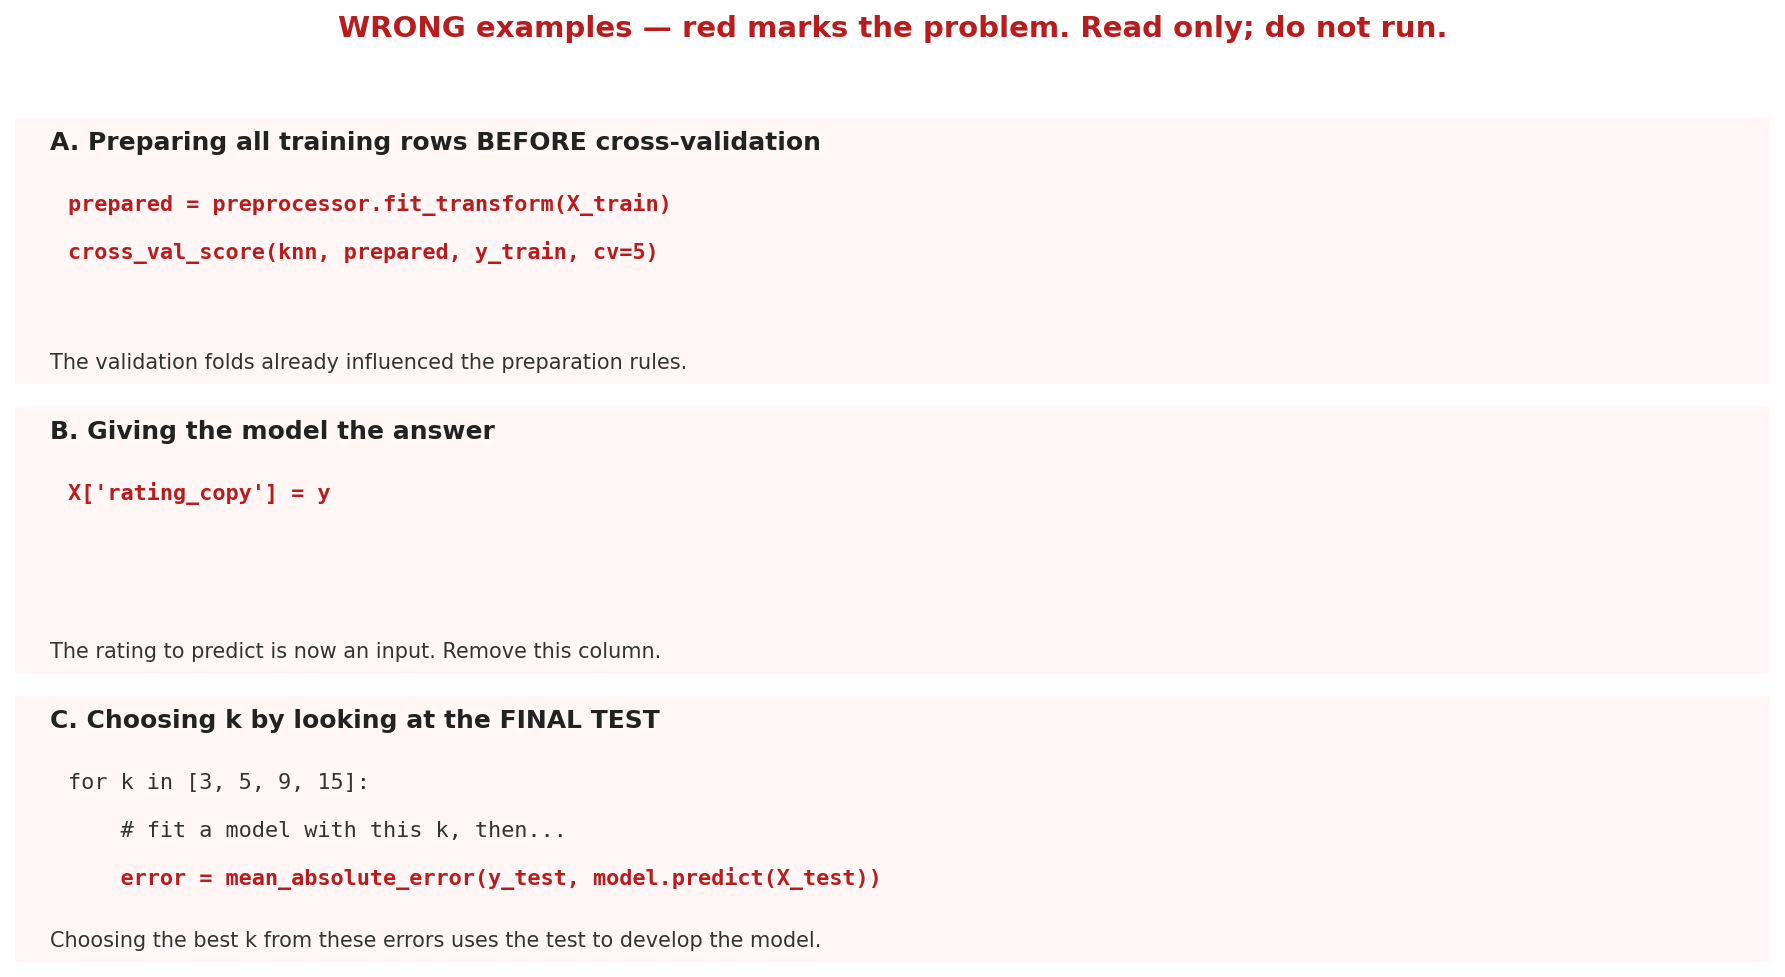

### A — Learning medians and scaling values from validation rows
Cleaning is necessary. Fixed rules such as removing spaces or converting text to numbers can be applied before splitting. But medians, means and scaling values must be learned only from the training part.

With cross-validation, do not calculate these values using all of X_train before creating the folds: some of those rows will be used for validation.

> **Fix:** pass the complete pipeline and the training data to cross-validation. It learns preprocessing separately inside each fold.

```python
# model contains both preprocessing and k-NN.
# Each fold learns its own medians and scaling values.
scores = cross_val_score(
    model, X_train, y_train,
    cv=5, scoring='neg_mean_absolute_error'
)
```

Validation values are still filled and scaled, using the rules learned from that fold's training rows. Applying training rules to validation is correct; using validation rows to calculate those rules is leakage.

### B — Putting the answer in X
`y` contains the rating we want to predict. Copying it into X lets the model see the answer.

**Fix:** use only the allowed film characteristics in X.

```python
X = movies[['release_year', 'genre_profile', 'genre_count']]
y = movies['mean_rating']
```

### C — Using the final test to choose k
If we try several values of k and keep the one with the lowest **test error**, we have used the exam to choose our model.

**Fix:** choose k using cross-validation on training data. Evaluate on the test after making that choice.

**Remember:** prepare inside the pipeline; keep the answer out of X; keep the final test until the end.

## 6. Cross-validation: see what changes each round
Cross-validation creates temporary fitting and validation partitions **within X_train**. Each round fits a fresh copy of the entire pipeline; its score comes from rows not used to fit that copy.

Start with **KFold** for the movie exercise. The other illustrated methods are a reference for choosing a suitable strategy.

In the diagrams, each column is an observation in the training pool. Blue fits the pipeline, orange validates it, and grey is unused in that round. The final test is absent from these diagrams because it remains reserved.

To evaluate a model, we must **fit it on training and score it on validation**. The errors from each fold are averaged to estimate the model's performance.

### 6.1 KFold — the method we use for movies
Split the training rows into five parts. Use four parts to fit and one part to validate. Repeat five times, changing the validation part each time.

We get five error values and calculate their average. The final test is not involved.

In the generic example, `pipeline` means the complete preparation + model pipeline. In our movie code, that object is called `model`.

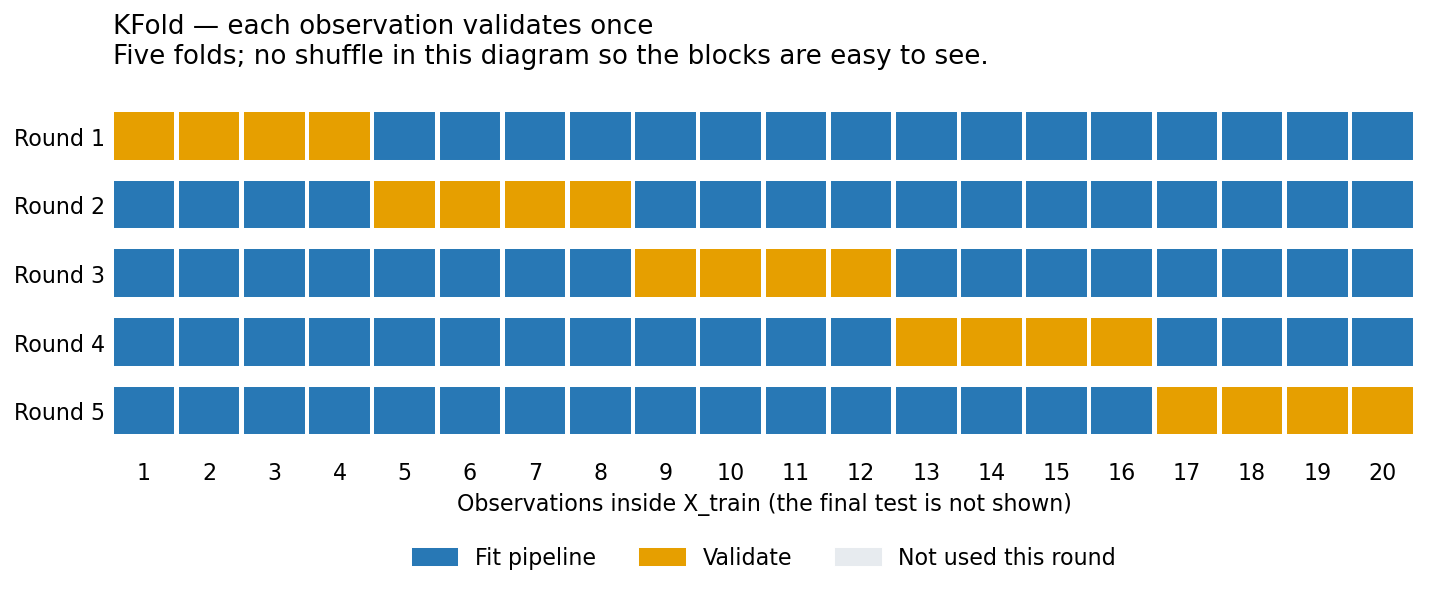

>**Example**
>
>```python
>from sklearn.model_selection import KFold, cross_val_score
>
>cv = KFold(n_splits=5, shuffle=True, random_state=42)
>scores = cross_val_score(
>    pipeline, X_train, y_train,
>    cv=cv, scoring='neg_mean_absolute_error'
>)
>print('Mean MAE:', -scores.mean())
>```

### 6.2 StratifiedKFold — classification

Keep approximately the same class proportions in each fold. Stratification also helps when classes are imbalanced. It does not balance the training data or prevent group/time leakage.

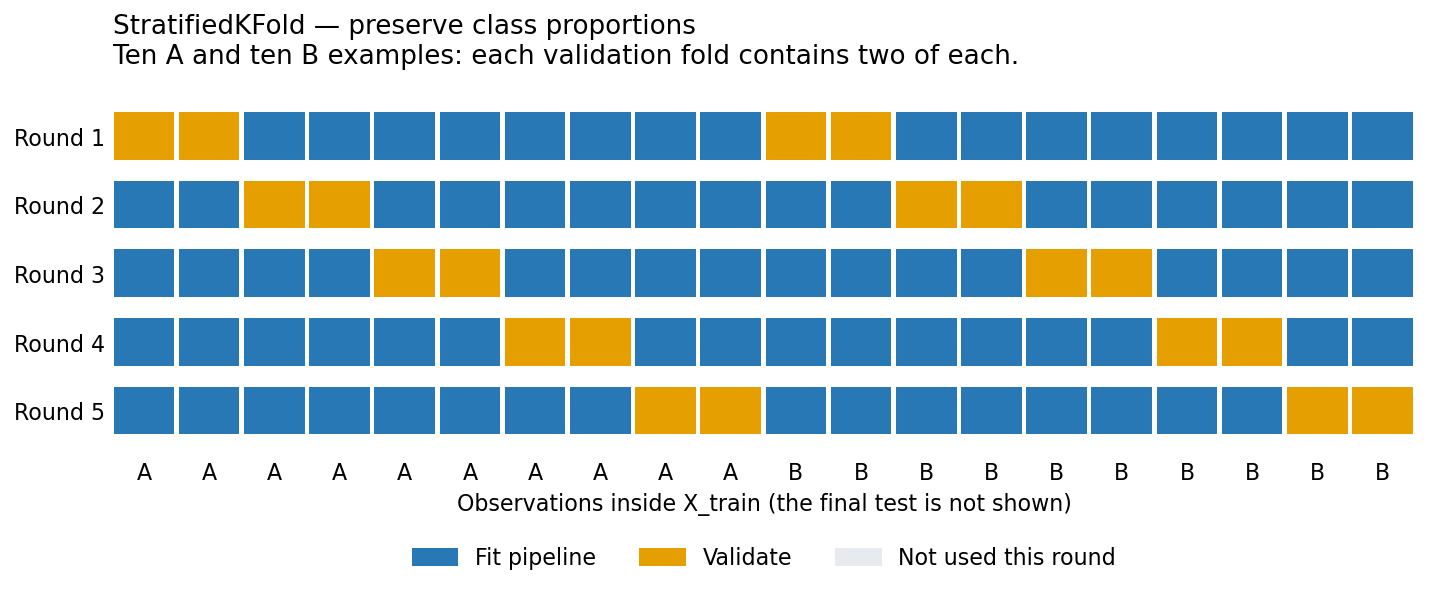

>**Example**
>
>```python
>from sklearn.model_selection import StratifiedKFold, cross_val_score
>
>cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
>scores = cross_val_score(
>    classifier_pipeline, X_train, y_train,
>    cv=cv, scoring='f1_macro'
>)
>print('Mean macro-F1:', scores.mean())
>```

### 6.3 GroupKFold — keep related rows together
Imagine several rows belonging to the same person. To evaluate predictions for new people, keep every row from one person on the same side of each split.

`groups` tells scikit-learn which person each row belongs to. The final test must also contain separate people.

This is a reference example; use KFold for our movie exercise.

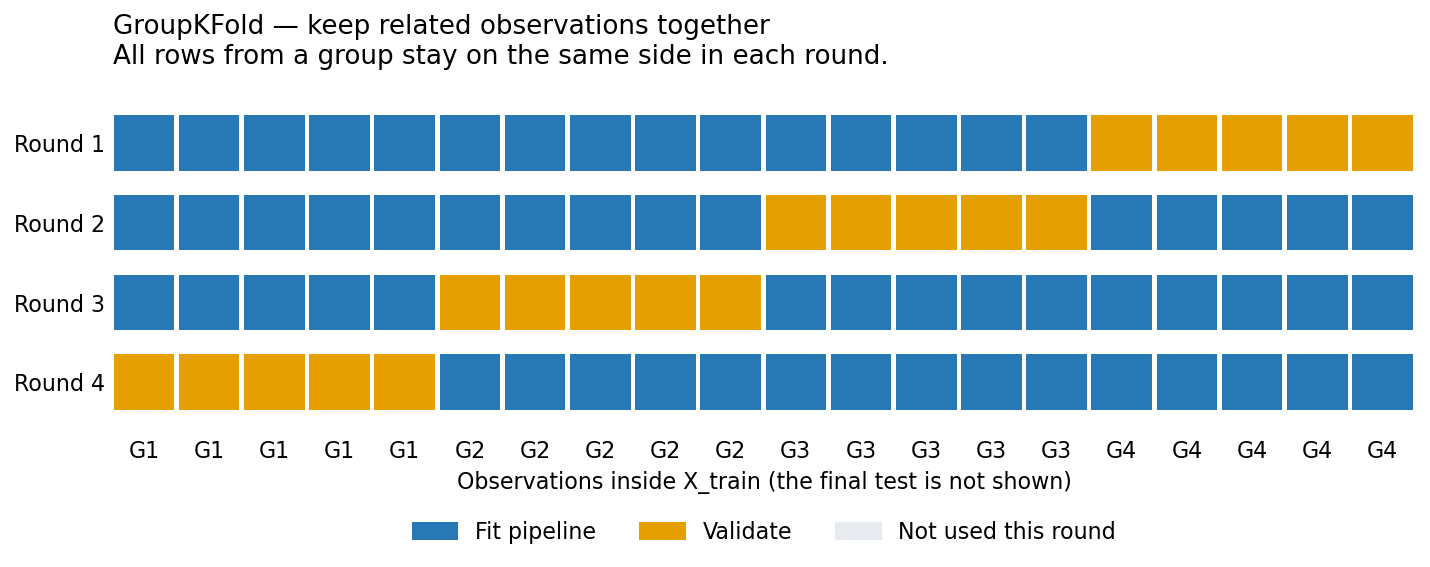

**Example**
>
>```python
>from sklearn.model_selection import GroupKFold, cross_val_score
>
># group_ids_train is aligned row-for-row with X_train.
>cv = GroupKFold(n_splits=4)
>scores = cross_val_score(
>    pipeline, X_train, y_train,
>    groups=group_ids_train, cv=cv,
>    scoring='neg_mean_absolute_error'
>)
>
>```
>**Choose for:** unseen-group prediction, with at least as many groups as folds.
>- This pattern assumes scikit-learn's default metadata routing setting.
>- For classification with both group constraints and class imbalance, investigate `StratifiedGroupKFold`.

### Which one should I use?
| Situation | Starting choice |
| --- | --- |
| Independent observations, regression | KFold |
| Independent observations, classification | StratifiedKFold |
| Repeated rows from one entity | GroupKFold |

**Important**: Cross-validation is a procedure for evaluation/selection, not a replacement for the final test and not a guarantee against every form of leakage.

In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print('We will use 5 validation rounds inside the training data.')

We will use 5 validation rounds inside the training data.


### What happens inside this call?

```python
scores = cross_val_score(
    model, X_train, y_train,
    cv=5,
    scoring='neg_mean_absolute_error',
)
```

**Only X_train and y_train enter this call. X_test is not used.**

In each of the five rounds:

```text
X_train
├── 4 parts: learn medians and scaling values, then fit the model
└── 1 part: apply those SAME values, predict, and measure the error
```

1. A fresh copy of the pipeline receives the four training parts.
2. The imputer calculates medians from those parts and fills their missing values.
3. The scaler learns its mean and standard deviation from that prepared training data.
4. The model is fitted on the prepared training rows and their y values.
5. The validation part is filled and scaled with the SAME learned values, then used to measure prediction error.

The validation part changes in the next round. **The medians, scaling values and model are learned again from the new training parts.** Missing validation values are filled; they are not left empty.

**Where is fit?** `cross_val_score` calls it automatically on a fresh pipeline copy in every round. You do not need to fit the pipeline before calling cross-validation.

**After cross-validation:** the scores describe the validation results; they are not a final fitted model. To fit the final pipeline, use `model.fit(X_train, y_train)`. With `GridSearchCV`, this final fit is already performed by default after selecting the best parameters. The final test is then transformed using the values learned from all training rows.


### Q6.1 — Run cross-validation
The code below is already completed. Run it and read the five MAE values.

`negative_scores` uses scikit-learn's negative-error convention. The minus sign in `fold_mae = -negative_scores` changes them back to ordinary positive errors.

**Question:** are the errors identical across the five rounds? Which number summarises the average error?

>**Note**
>
>- The five errors differ because each fold contains different films. Their mean is **0.316 rating points**.
>- The standard deviation describes how much these five results vary; it is not automatically a confidence interval.

In [10]:
negative_scores = cross_val_score(
    model, X_train, y_train, cv=cv,
    scoring='neg_mean_absolute_error', n_jobs=1,
)
fold_mae = -negative_scores

display(pd.DataFrame({'fold': range(1, 6), 'mae': fold_mae}))
print('Mean MAE:', fold_mae.mean())
print('Standard deviation:', fold_mae.std())

,fold,mae
0,1,0.316838
1,2,0.320344
2,3,0.326152
3,4,0.306848
4,5,0.311775


Mean MAE: 0.3163914664284465
Standard deviation: 0.006685608239117816


## 7. GridSearchCV — try several values of k
We now ask: **how many neighbours should we use?**

`GridSearchCV` automates this comparison:
1. Try k = 3, 5, 9 and 15.
2. Run cross-validation for each value.
3. Choose the value with the lowest average MAE.
4. Fit that choice on all training rows.

`model__n_neighbors` means: change `n_neighbors` in the pipeline step named `model`.

We change only k in this exercise. There are 4 choices × 5 folds = 20 CV fits, then one final fit on training. The test is still untouched.

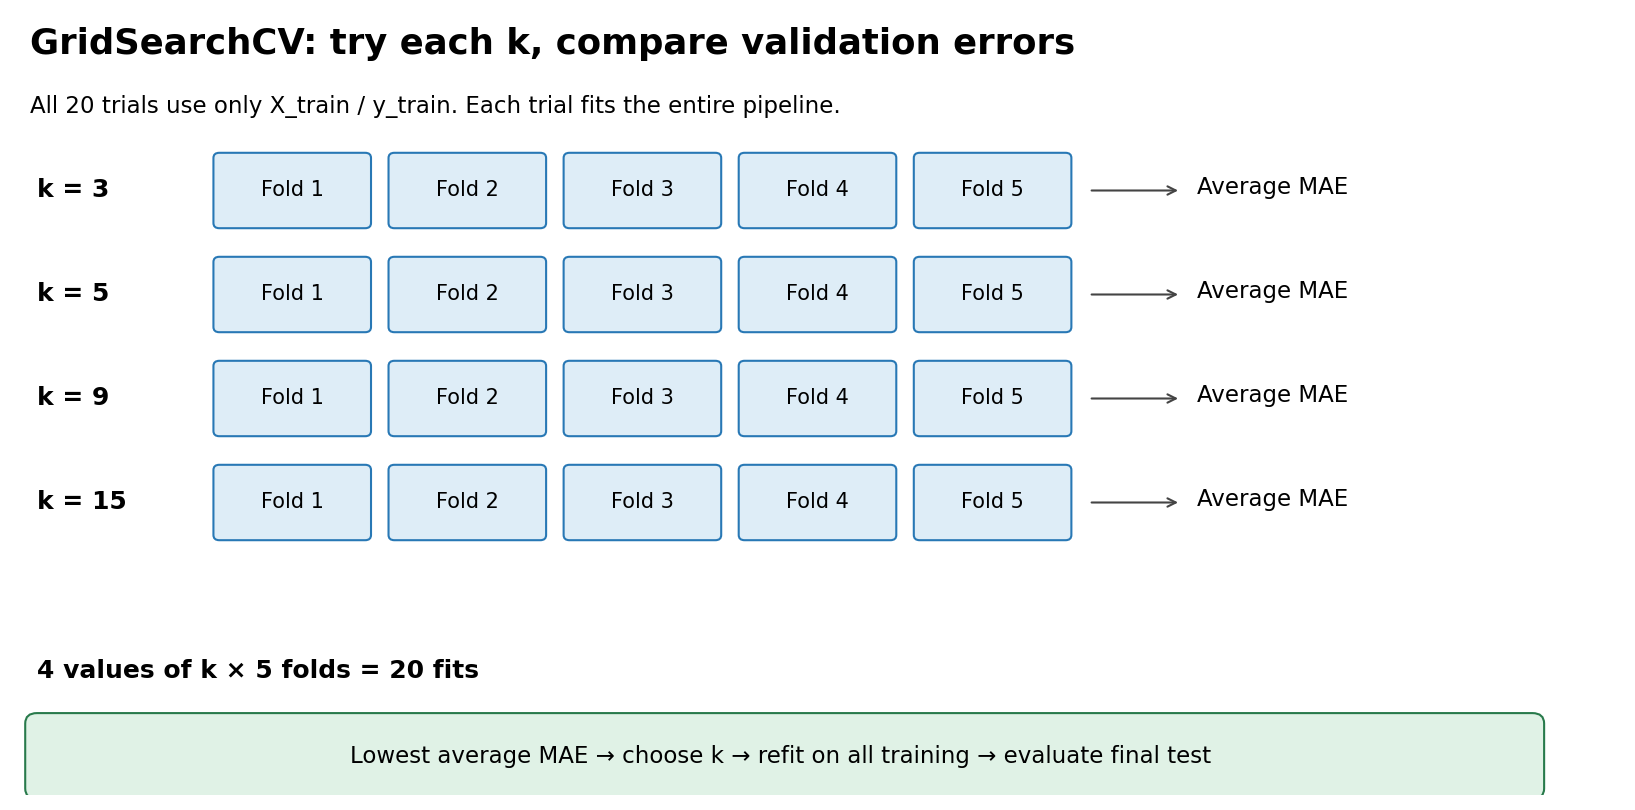

### Generic example — the same pattern for another dataset
`pipeline` must contain the preparation and the model. Here the model step is named `model`.

> **Example**
> ```python
>
> grid = {'model__n_neighbors': [3, 5, 9, 15]}
> search = GridSearchCV(
>     pipeline, grid, cv=5,
>     scoring='neg_mean_absolute_error'
> )
> search.fit(X_train, y_train)
> print(search.best_params_)
> ```

The following cell applies this pattern to our movie pipeline. No new preprocessing pipeline is needed.

### Q7.1 — Run the search
Run the supplied code. Which value of k was selected? What is its average CV MAE?

Do not use X_test or y_test here.

**Suggested answer / teaching note**

The search selects **k = 15**, with average CV MAE **0.304**. Four choices and five folds require 20 CV fits, followed by one refit of the selected pipeline on all training rows.

### Watch the search while it runs
`verbose=2` prints a short message for each completed fold/configuration. `n_jobs=1` runs them one at a time, making the log easier to follow.

You will first see a message like:
```text
Fitting 5 folds for each of 4 candidates, totalling 20 fits
```
Here **candidate** means a value of k; **fit** means one training/validation trial. The final refit on all training data is additional.

This is a text progress log, not a live chart. Our dataset is small, so it may finish quickly. After it finishes, the next cells show the results visually.

Use `verbose=0` later if you prefer quiet output. [GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).


In [11]:
param_grid = {'model__n_neighbors': [3, 5, 9, 15]}

search = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    verbose=2,  # show completed trials
    n_jobs=1,   # run one trial at a time
)
search.fit(X_train, y_train)

print('Best k:', search.best_params_['model__n_neighbors'])
print('Average CV MAE:', -search.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END ...............................model__n_neighbors=3; total time=   0.0s
[CV] END ...............................model__n_neighbors=3; total time=   0.0s
[CV] END ...............................model__n_neighbors=3; total time=   0.0s
[CV] END ...............................model__n_neighbors=3; total time=   0.0s
[CV] END ...............................model__n_neighbors=3; total time=   0.0s


[CV] END ...............................model__n_neighbors=5; total time=   0.0s


[CV] END ...............................model__n_neighbors=5; total time=   0.0s
[CV] END ...............................model__n_neighbors=5; total time=   0.0s
[CV] END ...............................model__n_neighbors=5; total time=   0.0s
[CV] END ...............................model__n_neighbors=5; total time=   0.0s
[CV] END ...............................model__n_neighbors=9; total time=   0.0s
[CV] END ...............................model__n_neighbors=9; total time=   0.0s
[CV] END ...............................model__n_neighbors=9; total time=   0.0s


[CV] END ...............................model__n_neighbors=9; total time=   0.0s


[CV] END ...............................model__n_neighbors=9; total time=   0.0s
[CV] END ..............................model__n_neighbors=15; total time=   0.0s
[CV] END ..............................model__n_neighbors=15; total time=   0.0s
[CV] END ..............................model__n_neighbors=15; total time=   0.0s
[CV] END ..............................model__n_neighbors=15; total time=   0.0s
[CV] END ..............................model__n_neighbors=15; total time=   0.0s


Best k: 15
Average CV MAE: 0.3037710410009318


### Q7.2 — Compare the four choices
The table below shows one row per value of k. Lower MAE is better.

Which k has the smallest error? Are the differences large or small?

**Suggested answer / teaching note**

**k = 15** has the lowest mean error in this run. Read the size of the differences from the table: small differences are not evidence of a large improvement. The green table cell and bar identify the CV winner, not a test-set winner.

In [12]:
results = pd.DataFrame(search.cv_results_)
comparison = pd.DataFrame({
    'k': results['param_model__n_neighbors'],
    'CV MAE': -results['mean_test_score'],
})
display(
    comparison.sort_values('CV MAE').style
    .format({'CV MAE': '{:.3f}'})
    .highlight_min(subset=['CV MAE'], color='lightgreen')
)

,k,CV MAE
3,15,0.304
2,9,0.307
1,5,0.316
0,3,0.333


### See which k worked best
The green table cell marks the lowest average CV error. In the plot, **a shorter bar is better**. Each bar summarises five validation folds; it is not a test-set score.

This chart is created **after** the search. It helps compare the candidates; it is not a live progress bar. The plotting code is supplied — just run it.

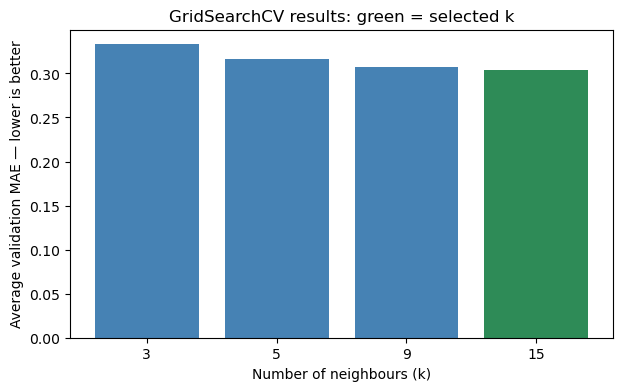

In [13]:
plot_data = comparison.sort_values('k')
best_k = search.best_params_['model__n_neighbors']
colors = ['seagreen' if k == best_k else 'steelblue' for k in plot_data['k']]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(plot_data['k'].astype(str), plot_data['CV MAE'], color=colors)
ax.set_xlabel('Number of neighbours (k)')
ax.set_ylabel('Average validation MAE — lower is better')
ax.set_title('GridSearchCV results: green = selected k')
plt.show()

**A confusing scikit-learn name:** `mean_test_score` here means the average score of the **validation folds**. It does not mean we used our final X_test.

### Q7.3 — Is k-NN better than a simple guess?
The baseline predicts the training median for every film. Run the supplied comparison on the same CV folds.

Choose the model with lower average MAE **before** looking at the test.

**Suggested answer / teaching note**

Baseline CV MAE: **0.346**. Selected k-NN CV MAE: **0.304**. We choose **k-NN** using these CV results, before consulting the test. A baseline can win on other datasets; a more complex model is not automatically better.

In [14]:
baseline_scores = cross_val_score(
    baseline, X_train, y_train,
    cv=cv, scoring='neg_mean_absolute_error',
)
baseline_cv_mae = -baseline_scores.mean()
knn_cv_mae = -search.best_score_

print('Baseline CV MAE:', baseline_cv_mae)
print('k-NN CV MAE:', knn_cv_mae)

if knn_cv_mae < baseline_cv_mae:
    selected_name = 'k-NN'
else:
    selected_name = 'Median baseline'
print('Choice before the final test:', selected_name)

Baseline CV MAE: 0.3464841420597862
k-NN CV MAE: 0.3037710410009318
Choice before the final test: k-NN


### Q7.4 — Record your choice
Write down the chosen model, the best k, and the average CV MAE. Why must we make this choice before using the test?

**Suggested answer / teaching note**

Chosen model: **k-NN**. Selected k: **15**. Mean CV MAE: **0.304**. We record this now so the final test measures a decision already made. Choosing k from test errors would make the test part of model development.

## 8. Final test — evaluate the choice
We have finished choosing the model. Now we predict the reserved test films.

The baseline must be fitted on all training rows. GridSearchCV has already done this for its best pipeline.

We report both errors for comparison, but keep the choice made using CV. Do not change k after seeing the test results.

### Q8.1 — Read the final MAE
Run the code. Compare the two test errors with the earlier CV errors.

MAE is measured in rating points. Smaller is better. We use only MAE in this exercise.

**Suggested answer / teaching note**

Test MAE is **0.341** for k-NN and **0.368** for the baseline. Compare these with CV MAE of 0.304 and 0.346, respectively. Differences are expected because the test contains different films. Do not change k in response to the test results.

In [15]:
baseline.fit(X_train, y_train)
baseline_test_predictions = baseline.predict(X_test)
test_predictions = search.predict(X_test)

test_results = pd.DataFrame({
    'Model': ['Median baseline', 'k-NN'],
    'Test MAE': [
        mean_absolute_error(y_test, baseline_test_predictions),
        mean_absolute_error(y_test, test_predictions),
    ],
})
display(test_results)
print('Model chosen using CV:', selected_name)

,Model,Test MAE
0,Median baseline,0.367664
1,k-NN,0.340621


Model chosen using CV: k-NN


## 9. Look at the mistakes
The supplied code shows the k-NN predictions. In the plot, points close to the dashed line are better predictions.

Use this to explain errors, not to change the model using test results.

,movieId,title,rating_count,actual,predicted,absolute_error
643,2720,Inspector Gadget (1999),21,2.095238,3.311149,1.215911
598,2428,"Faculty, The (1998)",23,2.478261,3.615790,1.137529
1158,63992,Twilight (2008),22,2.409091,3.545634,1.136544
554,2253,Toys (1992),20,2.375000,3.430746,1.055746
722,3264,Buffy the Vampire Slayer (1992),26,2.423077,3.383591,0.960514
259,1021,Angels in the Outfield (1994),27,2.333333,3.232679,0.899345
591,2410,Rocky III (1982),24,2.729167,3.588243,0.859076
286,1091,Weekend at Bernie's (1989),21,2.547619,3.385207,0.837588


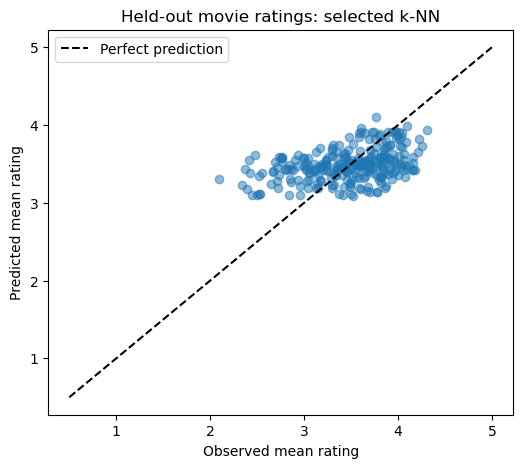

In [16]:
audit = movies.loc[X_test.index, ['movieId', 'title', 'rating_count']].copy()
audit['actual'] = y_test
audit['predicted'] = test_predictions
audit['absolute_error'] = (audit['actual'] - audit['predicted']).abs()
display(audit.sort_values('absolute_error', ascending=False).head(8))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, test_predictions, alpha=0.5)
ax.plot([0.5, 5], [0.5, 5], '--', color='black', label='Perfect prediction')
ax.set(xlabel='Observed mean rating', ylabel='Predicted mean rating',
       title='Held-out movie ratings: selected k-NN')
ax.legend()
plt.show()

### Q9.1 — Explain the result simply
Write three short answers:
1. Did k-NN beat the baseline on the test?
2. Name one film with a large prediction error.
3. Why might year and genres be insufficient to predict a film's rating?

**Suggested answer / teaching note**

1. Yes: k-NN test MAE is 0.341, versus 0.368 for the baseline.
2. **Inspector Gadget (1999)** has observed mean rating 2.10, prediction 3.31, and absolute error 1.22.
3. Films with the same year and genres can differ in writing, acting, direction and audience. These features cannot capture everything that affects ratings, and the ratings reflect this particular sample of users.

## 10. Transfer to your Week 6 dataset
This section prepares Mini-project 3; it is not an extra project submission. Reuse your dataset knowledge and deterministic cleaning rules, but revisit any imputation/scaling that previously used the full dataset.

| Dataset | Suggested target | Estimator / metric | Split concern |
| --- | --- | --- | --- |
| Student Performance | `final_grade` | k-NN regressor / MAE | Define the prediction moment before deciding whether `grade_1` and `grade_2` are available |
| Bike Sharing | `rentals` | k-NN regressor / MAE | For future-day prediction, use chronological holdout and `TimeSeriesSplit`; exclude `casual` and `registered`, which compose the target |
| Auto MPG | `mpg` | k-NN regressor / MAE | Exclude record IDs; justify whether the task concerns similar vehicles or later model years |
| Palmer Penguins | `species` | k-NN classifier / macro-F1 | Use suitable stratified splits; never include species or its encoding in X |

For classification, use a classification baseline such as `DummyClassifier(strategy='most_frequent')`. Keep workload comparable: one baseline, one model family, and a small search. A classification metric is not appropriate for the movie regression example.

### Q10.1 — Apply the same steps to your dataset
Name your target, input columns, metric and CV method. Identify one column or procedure that could cause leakage.

Follow the same route: **split → pipeline → cross-validation → GridSearchCV → final test**.

**Suggested answer / teaching note**

One valid plan per dataset is shown below; other choices need a clear prediction task and justification.

| Dataset | Target and inputs | Metric / validation | Leakage to avoid |
| --- | --- | --- | --- |
| Student Performance | Predict final_grade at the start of the course from information available then | MAE; KFold if rows are independent | Exclude grade_1 and grade_2 for this prediction moment; keep imputation inside folds |
| Bike Sharing | Predict rentals for later dates using calendar information and weather inputs available at the prediction moment | MAE; chronological test and TimeSeriesSplit | Exclude casual and registered; do not use actual future weather if only forecasts would be available |
| Auto MPG | Predict mpg for similar vehicles using cylinders, horsepower, weight and origin | MAE; KFold for this same-population task | Exclude IDs and mpg from X; impute and scale within the pipeline |
| Penguins | Predict species from bill dimensions, flipper length and body mass | Macro-F1; stratified split and StratifiedKFold | Exclude species and any encoding of it from X |

For classification use `KNeighborsClassifier` and a classification baseline. For regression use `KNeighborsRegressor` and a median baseline. Adapt the split when rows are related or the aim is prediction for later years.

## Completion checklist
- [ ] I can explain why mean_rating, IDs and rating_count are not predictors here.
- [ ] My train/test split and internal CV folds follow the stated protocol.
- [ ] Learned preprocessing runs inside the full pipeline and each CV fold.
- [ ] I compared a baseline and interpreted MAE in rating points.
- [ ] I understand the negative scoring convention and `model__` parameter names.
- [ ] I recorded decisions before inspecting the final test.
- [ ] I reported limitations, even if the model did not beat the baseline.


## References
- [scikit-learn: common pitfalls and leakage](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [MovieLens latest-small](https://grouplens.org/datasets/movielens/latest/)
- Harper and Konstan (2015), *The MovieLens Datasets: History and Context*, [doi:10.1145/2827872](https://doi.org/10.1145/2827872).

> Now celebrate: your model can predict ratings for unseen films! 🍿<br>
> Time to watch The Great Gatsby (2013) — because after all these pipelines, you deserve a party.<br>
> Just keep your training and test data off each other’s guest lists. 😉

## Final Summary — From Train/Test Split to Final Evaluation

This is a recap of the workflow above. It is shown as reference code, so it does not rerun the experiment or change the saved results.

The movie data contain both numeric and categorical columns. The preprocessing steps are defined explicitly below: numeric columns are imputed and scaled; categorical columns are imputed and encoded. A pipeline with only a numeric imputer and scaler would not handle the genre text.

```python
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error

# 1. Separate training data from the reserved final test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 2. Define preprocessing + model. Nothing is learned here.
numeric_features = ["release_year", "genre_count"]
categorical_features = ["genre_profile"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore", sparse_output=False
    )),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Use the k selected earlier by GridSearchCV on training data only.
pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", KNeighborsRegressor(
        n_neighbors=search.best_params_["model__n_neighbors"]
    )),
])

# 3. Evaluate with cross-validation inside the training data.
# Each fold fits a fresh pipeline copy, including its imputer and scaler.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(
    pipeline, X_train, y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
)
print("Mean validation MAE:", -scores.mean())

# 4. Fit the final pipeline using all training data.
# Learn the final medians, scaling values and model from training only.
pipeline.fit(X_train, y_train)

# 5. Apply the learned preprocessing rules to the reserved test and predict.
# predict does not recalculate medians or scaling values from test data.
predictions = pipeline.predict(X_test)
print("Test MAE:", mean_absolute_error(y_test, predictions))
```

**Where GridSearchCV fits in:** earlier, it compared several values of k using cross-validation on training data. Its default `refit=True` then fitted the selected pipeline on all training rows. Therefore, in the main workflow, `search.predict(X_test)` already performs the final prediction; the explicit `pipeline.fit(...)` above illustrates that final fitting step.

The CV score for the selected k is a development score, not an independent evaluation of the selection procedure. Keep the reserved test for the final assessment. This recap does not authorise changing k after seeing test results.

**Remember the order:** split → define pipeline → validate/select on training → fit on all training → evaluate on the reserved test.
